## Partie 1 — Explorer et vérifier les données

In [1]:
import pandas as pd

df = pd.read_csv("transactions_TP2.csv")

In [2]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [3]:
df.shape

(3045, 12)

In [4]:
df.dtypes

id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object

In [5]:
missing = pd.DataFrame({
    "Nombre": df.isnull().sum(),
    "Pourcentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Pourcentage",
    ascending=False
)

missing

,Nombre,Pourcentage
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


In [6]:
df["id_operation"].duplicated().sum()

np.int64(45)

In [7]:
df = df.drop_duplicates(subset="id_operation")

In [8]:
df.shape

(3000, 12)

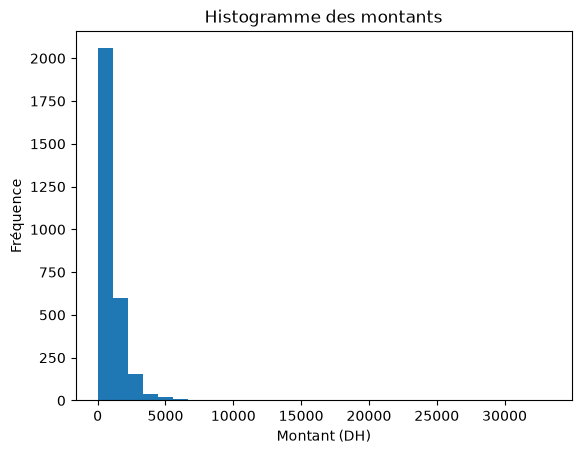

In [9]:
import matplotlib.pyplot as plt

plt.hist(df["montant_dh"].dropna(), bins=30)
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.title("Histogramme des montants")
plt.show()

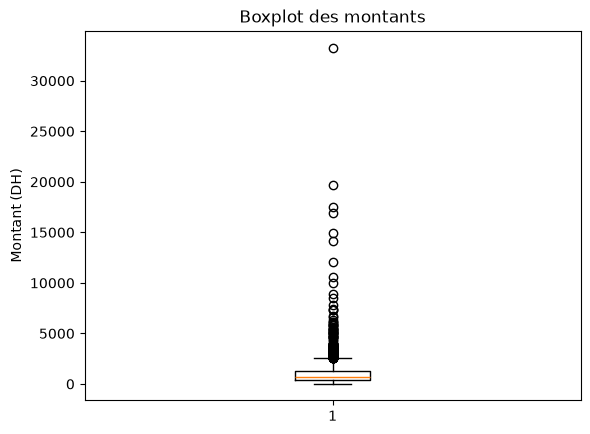

In [10]:
plt.boxplot(df["montant_dh"].dropna())
plt.ylabel("Montant (DH)")
plt.title("Boxplot des montants")
plt.show()

In [11]:
df["montant_dh"].nlargest(5)

2660    33281.23
539     19658.42
1775    17496.64
1557    16962.99
2556    14951.95
Name: montant_dh, dtype: float64

In [12]:
df["montant_dh"].nsmallest(5)

2694    36.41
783     43.86
2400    57.07
2626    58.30
366     60.79
Name: montant_dh, dtype: float64

In [13]:
df["fraude"].value_counts()

fraude
0    2742
1     258
Name: count, dtype: int64

In [14]:
df["fraude"].value_counts(normalize=True) * 100

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64

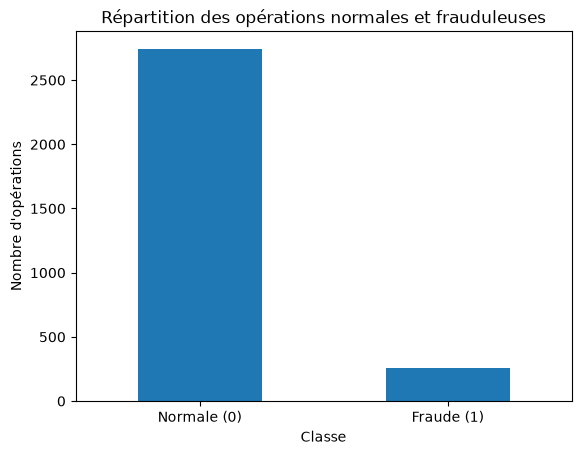

In [15]:
df["fraude"].value_counts().plot(kind="bar")

plt.xlabel("Classe")
plt.ylabel("Nombre d'opérations")
plt.title("Répartition des opérations normales et frauduleuses")
plt.xticks([0, 1], ["Normale (0)", "Fraude (1)"], rotation=0)
plt.show()

In [16]:
df.columns

Index(['id_operation', 'id_client', 'montant_dh', 'anciennete_mois',
       'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international',
       'resultat_enquete', 'fraude'],
      dtype='str')

## Partie 2 — Préparer les données sans fuite

In [17]:
y = df["fraude"]

X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])

In [18]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)


In [19]:
from sklearn.model_selection import train_test_split

X_ref, X_ver, y_ref, y_ver = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
print("X_ref :", X_ref.shape)
print("X_ver :", X_ver.shape)
print("y_ref :", y_ref.shape)
print("y_ver :", y_ver.shape)

X_ref : (2400, 8)
X_ver : (600, 8)
y_ref : (2400,)
y_ver : (600,)


In [21]:
print("Proportion dans Référence :")
print(y_ref.value_counts(normalize=True) * 100)

print("\nProportion dans Vérification :")
print(y_ver.value_counts(normalize=True) * 100)

Proportion dans Référence :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Proportion dans Vérification :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


In [22]:
X.dtypes

montant_dh         float64
anciennete_mois    float64
nb_ops_24h         float64
heure                int64
canal                  str
appareil               str
region                 str
international          str
dtype: object

In [23]:
numeric_features = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"
]

In [24]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [25]:
from sklearn.preprocessing import OneHotEncoder

In [26]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [27]:
from sklearn.compose import ColumnTransformer

In [29]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [30]:
categorical_features = [
    "canal",
    "appareil",
    "region",
    "international"
]

In [31]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [32]:
preprocessor.fit(X_ref)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [33]:
X_ref_transformed = preprocessor.transform(X_ref)

In [34]:
X_ver_transformed = preprocessor.transform(X_ver)

In [36]:
imputer = preprocessor.named_transformers_["num"].named_steps["imputer"]

print("Médianes calculées sur X_ref :")
print(pd.Series(imputer.statistics_, index=numeric_features))

Médianes calculées sur X_ref :
montant_dh         710.79
anciennete_mois     87.00
nb_ops_24h           3.00
heure               11.00
dtype: float64


In [37]:
scaler = preprocessor.named_transformers_["num"].named_steps["scaler"]

print("Moyennes calculées sur X_ref :")
print(pd.Series(scaler.mean_, index=numeric_features))

print("\nÉcarts-types calculés sur X_ref :")
print(pd.Series(scaler.scale_, index=numeric_features))

Moyennes calculées sur X_ref :
montant_dh         1020.672925
anciennete_mois      87.483333
nb_ops_24h            2.720833
heure                11.470000
dtype: float64

Écarts-types calculés sur X_ref :
montant_dh         1327.625413
anciennete_mois      49.485921
nb_ops_24h            1.646076
heure                 6.995470
dtype: float64


In [38]:
from sklearn.preprocessing import RobustScaler

In [39]:
numeric_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

In [40]:
preprocessor_robust = ColumnTransformer(transformers=[
    ("num", numeric_pipeline_robust, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [42]:
preprocessor_robust.fit(X_ref)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [43]:
X_ref_robust = preprocessor_robust.transform(X_ref)

X_ver_robust = preprocessor_robust.transform(X_ver)

In [44]:
preprocessor.get_feature_names_out()

array(['num__montant_dh', 'num__anciennete_mois', 'num__nb_ops_24h',
       'num__heure', 'cat__canal_agence', 'cat__canal_application',
       'cat__canal_site_web', 'cat__canal_telephone',
       'cat__appareil_mobile', 'cat__appareil_ordinateur',
       'cat__appareil_terminal', 'cat__region_Autre',
       'cat__region_Casablanca-Settat', 'cat__region_Draa-Tafilalet',
       'cat__region_Marrakech-Safi', 'cat__region_Souss-Massa',
       'cat__international_non', 'cat__international_oui'], dtype=object)

In [45]:
comparaison = pd.DataFrame({
    "Montant_original": X_ref["montant_dh"].values,
    "StandardScaler": X_ref_transformed[:, 0],
    "RobustScaler": X_ref_robust[:, 0]
})

comparaison.sort_values(
    by="Montant_original",
    ascending=False
).head(5)

,Montant_original,StandardScaler,RobustScaler
88,33281.23,24.299442,39.892755
550,19658.42,14.038408,23.207337
1514,17496.64,12.410102,20.559557
532,14951.95,10.493379,17.442783
1317,14135.85,9.878673,16.443211


In [46]:
comparaison.sort_values(
    by="Montant_original"
).iloc[[len(comparaison)//2, -1]]

,Montant_original,StandardScaler,RobustScaler
2106,745.33,-0.207395,0.042305
2398,NaN,-0.233411,0.000000


In [47]:
comparaison_valides = comparaison.dropna(subset=["Montant_original"])

comparaison_valides = comparaison_valides.sort_values(
    by="Montant_original"
)

comparaison_valides.iloc[
    [len(comparaison_valides)//2, -1]
]

,Montant_original,StandardScaler,RobustScaler
1011,711.29,-0.233035,0.000612
88,33281.23,24.299442,39.892755


## Partie 3 — Comparer les méthodes de mise à l’échelle

In [48]:
Q1 = X_ref["montant_dh"].quantile(0.25)
Q3 = X_ref["montant_dh"].quantile(0.75)

IQR = Q3 - Q1

print("Q1 =", Q1)
print("Q3 =", Q3)
print("IQR =", IQR)

Q1 = 393.095
Q3 = 1249.8775
IQR = 856.7825


In [49]:
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

print("Limite inférieure =", limite_inf)
print("Limite supérieure =", limite_sup)

Limite inférieure = -892.0787499999999
Limite supérieure = 2535.05125


In [51]:
outliers = X_ref[
    (X_ref["montant_dh"] < limite_inf) |
    (X_ref["montant_dh"] > limite_sup)
]

print("Nombre de valeurs extrêmes :", len(outliers))

Nombre de valeurs extrêmes : 146


In [52]:
outliers["montant_dh"].sort_values(ascending=False).head(5)

2660    33281.23
539     19658.42
1775    17496.64
2556    14951.95
65      14135.85
Name: montant_dh, dtype: float64

In [53]:
X_ref_capped = X_ref.copy()

X_ref_capped["montant_dh"] = X_ref_capped["montant_dh"].clip(
    lower=limite_inf,
    upper=limite_sup
)

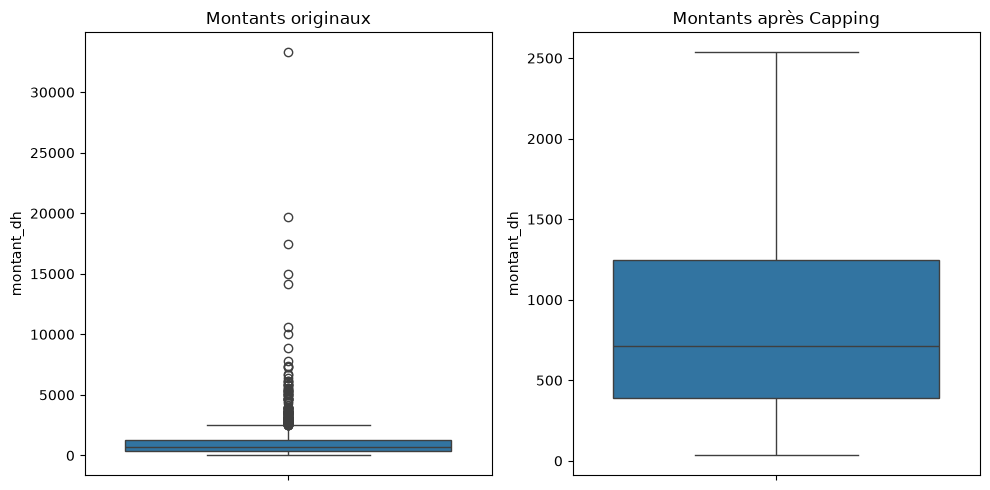

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=X_ref["montant_dh"])
plt.title("Montants originaux")

plt.subplot(1, 2, 2)
sns.boxplot(y=X_ref_capped["montant_dh"])
plt.title("Montants après Capping")

plt.tight_layout()
plt.show()

In [55]:
from sklearn.preprocessing import MinMaxScaler

In [56]:
minmax = MinMaxScaler()

minmax.fit(X_ref[["montant_dh"]])

montant_ref_minmax = minmax.transform(X_ref[["montant_dh"]])

montant_ver_minmax = minmax.transform(X_ver[["montant_dh"]])

In [57]:
standard = StandardScaler()

standard.fit(X_ref[["montant_dh"]])

montant_ref_standard = standard.transform(X_ref[["montant_dh"]])

montant_ver_standard = standard.transform(X_ver[["montant_dh"]])

In [58]:
robust = RobustScaler()

robust.fit(X_ref[["montant_dh"]])

montant_ref_robust = robust.transform(X_ref[["montant_dh"]])

montant_ver_robust = robust.transform(X_ver[["montant_dh"]])

In [59]:
comparaison_scaling = pd.DataFrame({
    "Montant_original": X_ver["montant_dh"].values,
    "MinMaxScaler": montant_ver_minmax.flatten(),
    "StandardScaler": montant_ver_standard.flatten(),
    "RobustScaler": montant_ver_robust.flatten()
})

comparaison_scaling.head()

,Montant_original,MinMaxScaler,StandardScaler,RobustScaler
0,795.50,0.022833,-0.175369,0.098870
1,1144.86,0.033342,0.083176,0.506628
2,259.10,0.006698,-0.572334,-0.527193
3,347.80,0.009367,-0.506691,-0.423666
4,451.36,0.012482,-0.430051,-0.302796


In [61]:
montants_valides = X_ver.dropna(subset=["montant_dh"])

montants_tries = montants_valides.sort_values("montant_dh")

montants_choisis = pd.concat([
    montants_tries.iloc[[len(montants_tries)//2 - 1,
                         len(montants_tries)//2,
                         len(montants_tries)//2 + 1]],
    montants_tries.iloc[[-1]]
])

montants_choisis[["montant_dh"]]

,montant_dh
93,681.89
1239,684.01
1529,689.79
1557,16962.99


In [62]:
tableau_final = montants_choisis[["montant_dh"]].copy()

tableau_final["MinMaxScaler"] = pd.Series(
    montant_ver_minmax.flatten(), index=X_ver.index
).loc[tableau_final.index]

tableau_final["StandardScaler"] = pd.Series(
    montant_ver_standard.flatten(), index=X_ver.index
).loc[tableau_final.index]

tableau_final["RobustScaler"] = pd.Series(
    montant_ver_robust.flatten(), index=X_ver.index
).loc[tableau_final.index]

tableau_final

,montant_dh,MinMaxScaler,StandardScaler,RobustScaler
93,681.89,0.019416,-0.259447,-0.033731
1239,684.01,0.019480,-0.257878,-0.031256
1529,689.79,0.019654,-0.253600,-0.024510
1557,16962.99,0.509149,11.789449,18.968875


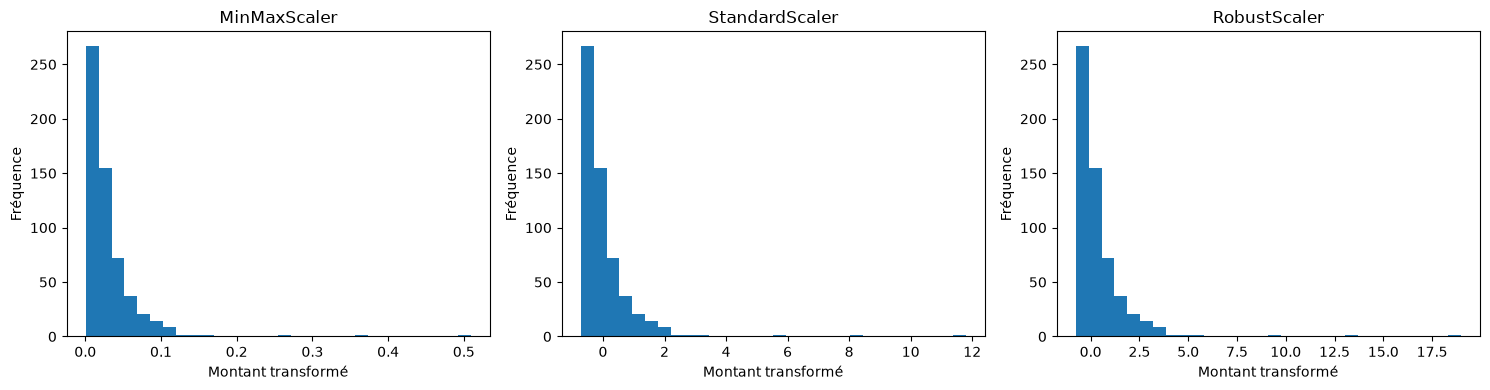

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=False)

axes[0].hist(montant_ver_minmax.flatten(), bins=30)
axes[0].set_title("MinMaxScaler")

axes[1].hist(montant_ver_standard.flatten(), bins=30)
axes[1].set_title("StandardScaler")

axes[2].hist(montant_ver_robust.flatten(), bins=30)
axes[2].set_title("RobustScaler")

for ax in axes:
    ax.set_xlabel("Montant transformé")
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

In [65]:
from sklearn.preprocessing import MinMaxScaler

montants_ref = [[100], [200], [300]]

scaler = MinMaxScaler()

scaler.fit(montants_ref)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](1,)",[300.]
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](1,)",[100.]
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](1,)",[200.]
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](1,)",[-0.5]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,3
"scale_ scale_: ndarray of shape (n_features,)Per feature relative scaling of the data. Equivalent to``(max - min) / (X.max(axis=0) - X.min(axis=0))``.. versionadded:: 0.17 *scale_* attribute.","ndarray[float64](1,)",[0.01]


In [66]:
nouvelle_transaction = [[400]]

montant_transformé = scaler.transform(nouvelle_transaction)

print(montant_transformé)

[[1.5]]
